In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [98]:
df = pd.read_csv('metadata.csv')

In [99]:
df.head()

,type,start_time,ambient_temperature,battery_id,test_id,uid,filename,Capacity,Re,Rct
0,discharge,[2010. 7. 21. 15. 0. ...,4,B0047,0,1,00001.csv,1.6743047446975208,NaN,NaN
1,impedance,[2010. 7. 21. 16. 53. ...,24,B0047,1,2,00002.csv,NaN,0.05605783343888099,0.20097016584458333
2,charge,[2010. 7. 21. 17. 25. ...,4,B0047,2,3,00003.csv,NaN,NaN,NaN
3,impedance,[2010 7 21 20 31 5],24,B0047,3,4,00004.csv,NaN,0.05319185850921101,0.16473399914864734
4,discharge,[2.0100e+03 7.0000e+00 2.1000e+01 2.1000e+01 2...,4,B0047,4,5,00005.csv,1.5243662105099023,NaN,NaN


In [100]:
df.shape

(7565, 10)

In [101]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7565 entries, 0 to 7564
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   type                 7565 non-null   object
 1   start_time           7565 non-null   object
 2   ambient_temperature  7565 non-null   int64 
 3   battery_id           7565 non-null   object
 4   test_id              7565 non-null   int64 
 5   uid                  7565 non-null   int64 
 6   filename             7565 non-null   object
 7   Capacity             2794 non-null   object
 8   Re                   1956 non-null   object
 9   Rct                  1956 non-null   object
dtypes: int64(3), object(7)
memory usage: 591.1+ KB


In [102]:
df = df.drop(columns=['start_time','battery_id','filename','uid','test_id'])
df


,type,ambient_temperature,Capacity,Re,Rct
0,discharge,4,1.6743047446975208,NaN,NaN
1,impedance,24,NaN,0.05605783343888099,0.20097016584458333
2,charge,4,NaN,NaN,NaN
3,impedance,24,NaN,0.05319185850921101,0.16473399914864734
4,discharge,4,1.5243662105099023,NaN,NaN
...,...,...,...,...,...
7560,impedance,24,NaN,0.0968087979207628,0.15489738203707232
7561,discharge,4,1.0201379996149256,NaN,NaN
7562,charge,4,NaN,NaN,NaN
7563,discharge,4,0.9907591663373165,NaN,NaN


In [103]:
df['type'].value_counts()

type
charge       2815
discharge    2794
impedance    1956
Name: count, dtype: int64

In [104]:
df['ambient_temperature'].mean()

np.float64(20.0177131526768)

In [105]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7565 entries, 0 to 7564
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   type                 7565 non-null   object
 1   ambient_temperature  7565 non-null   int64 
 2   Capacity             2794 non-null   object
 3   Re                   1956 non-null   object
 4   Rct                  1956 non-null   object
dtypes: int64(1), object(4)
memory usage: 295.6+ KB


In [106]:
# # Convert 'Re', 'Rct', and 'Capacity' to numeric, invalid parsing will be set to NaN
df['Re'] = pd.to_numeric(df['Re'] , errors = 'coerce')
df['Rct'] =pd.to_numeric(df['Rct'] , errors = 'coerce')
df['Capacity'] = pd.to_numeric(df['Capacity'] , errors = 'coerce')

In [107]:
# Fill missing values in 'Re', 'Rct', and 'Capacity' with their respective means
df['Re'] = df['Re'].fillna(df['Re'].mean())
df['Rct'] = df['Rct'].fillna(df['Rct'].mean())
df['Capacity']=df['Capacity'].fillna(df['Capacity'].mean())
# df['Re'] = df['Re'].fillna(df['Re'].mean())

In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7565 entries, 0 to 7564
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   type                 7565 non-null   object 
 1   ambient_temperature  7565 non-null   int64  
 2   Capacity             7565 non-null   float64
 3   Re                   7565 non-null   float64
 4   Rct                  7565 non-null   float64
dtypes: float64(3), int64(1), object(1)
memory usage: 295.6+ KB


In [109]:
df

,type,ambient_temperature,Capacity,Re,Rct
0,discharge,4,1.674305,-4.976500e+11,1.055903e+12
1,impedance,24,1.326543,5.605783e-02,2.009702e-01
2,charge,4,1.326543,-4.976500e+11,1.055903e+12
3,impedance,24,1.326543,5.319186e-02,1.647340e-01
4,discharge,4,1.524366,-4.976500e+11,1.055903e+12
...,...,...,...,...,...
7560,impedance,24,1.326543,9.680880e-02,1.548974e-01
7561,discharge,4,1.020138,-4.976500e+11,1.055903e+12
7562,charge,4,1.326543,-4.976500e+11,1.055903e+12
7563,discharge,4,0.990759,-4.976500e+11,1.055903e+12


In [110]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

# Encodding

In [111]:

label_encoder = LabelEncoder()
df['type'] = label_encoder.fit_transform(df['type'])

# train test split

In [112]:
X = df.drop(columns = ['ambient_temperature'])
y = df['ambient_temperature']

In [113]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [114]:
X_train.shape

(6052, 4)

# Scalling 

In [115]:
# scaler = MinMaxScaler()

# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

   #         Switch from MinMaxScaler to StandardScaler
   # MinMaxScaler hard-codes strict[0, 1] minimum and maximum walls based on the training samples.
   # Any input above the maximum scales well above 1.0, creating extreme distortion.
   #  Replace it with StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [116]:
X_train_scaled

array([[ 1.42621066e+00, -2.80002760e-03,  1.71392551e+00,
        -1.71392551e+00],
       [ 1.51070032e-01, -4.30202247e-01, -5.83455928e-01,
         5.83455928e-01],
       [ 1.51070032e-01, -4.29410050e+00, -5.83455928e-01,
         5.83455928e-01],
       ...,
       [ 1.42621066e+00, -2.80002760e-03,  1.71392551e+00,
        -1.71392551e+00],
       [ 1.42621066e+00, -2.80002760e-03,  1.71392551e+00,
        -1.71392551e+00],
       [-1.12407060e+00, -2.80002760e-03, -5.83455928e-01,
         5.83455928e-01]], shape=(6052, 4))

# model Building

In [117]:
model = Sequential()

# Input layer and first hidden layer
model.add(Dense(units=64 , activation ='relu' , input_dim=X_train_scaled.shape[1]))
model.add(Dropout(0.2))

# Second hidden layer
model.add(Dense(units=32 , activation = 'relu'))
model.add(Dropout(0.2))

# Output layer with 1 unit (for regression output), using a linear activation
model.add(Dense(units=1 , activation = 'linear'))

# compile 
model.compile(optimizer='adam' , loss = 'mean_squared_error')

C:\Users\sumit\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [118]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 64)                  │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,433 (9.50 KB)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 0 (0.00 B)

In [119]:
# Train the model on the traning data , using the test data for validation 

In [128]:

history = model.fit(X_train_scaled, y_train, epochs=146, batch_size=32, validation_data=(X_test_scaled, y_test))


Epoch 1/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 83.3515 - val_loss: 6953.9028
Epoch 2/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 83.6635 - val_loss: 6440.0825
Epoch 3/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 83.7143 - val_loss: 8839.9990
Epoch 4/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 84.0720 - val_loss: 6886.1724
Epoch 5/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 84.1009 - val_loss: 7388.5117
Epoch 6/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 83.0013 - val_loss: 6243.6484
Epoch 7/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 83.3431 - val_loss: 6172.9248
Epoch 8/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 84.2447 - val_loss: 6980.7349
Epoch 9/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 83.6449 - val_loss: 8372.7861
Epoch 10/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 83.4358 - val_loss: 7791.4985
Epoch 11/146
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 84.0767 - val_loss: 5

# Model Evaluation

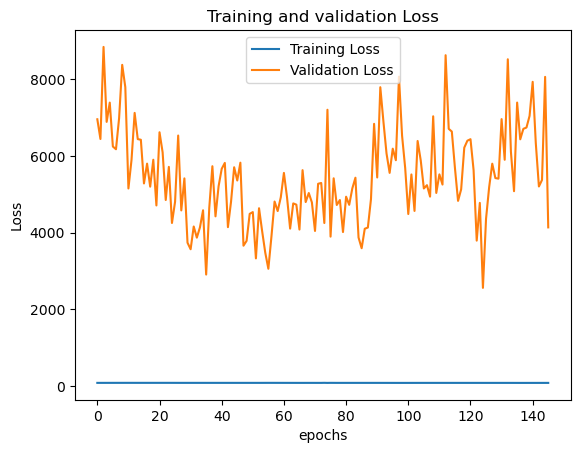

In [129]:
plt.plot(history.history['loss'] , label = 'Training Loss')
plt.plot(history.history['val_loss'] , label = 'Validation Loss')
plt.legend()
plt.xlabel('epochs')
plt.ylabel('Loss')
plt.title('Training and validation Loss')
plt.show()

In [130]:
mse = model.evaluate(X_test_scaled , y_test)

print(f'mean Squared error on test set : {mse}')

48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 4136.1426
mean Squared error on test set : 4136.142578125


# Prediction System

In [131]:
import numpy as np

def predict_battery_life(type_discharge, Capacity, Re, Rct, label_encoder, scaler, model):
    
    # Encode the categorical feature
    type_discharge_encoded = label_encoder.transform([type_discharge])[0]
    
    # Prepare the input feature vector
    X_input = np.array([[type_discharge_encoded,Capacity, Re, Rct]])
    
    # Scale the input features using the same scaler
    X_input_scaled = scaler.transform(X_input)
    
    # Predict the battery life (ambient_temperature)
    predicted_battery_life = model.predict(X_input_scaled)
    
    return predicted_battery_life[0]

In [132]:
# Example usage of the function
type_discharge = 'discharge'  # Example input for type
Capacity = 1.674305           # Example numeric value
Re = -4.976500e+11            # Example numeric value
Rct = 1.055903e+12            # Example numeric value

# Call the prediction function
predicted_battery_life = predict_battery_life(type_discharge, Capacity, Re, Rct, label_encoder, scaler, model)

print(f"Predicted Battery Life: {predicted_battery_life}")

C:\Users\sumit\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step
Predicted Battery Life: [27.238512]


In [137]:
# Example usage of the function with new input values
type_discharge = 'charge'  # New input for type
Capacity = 20.5            # Example numeric value for Capacity
Re = -2.983215e+11         # Example numeric value for Re
Rct = 1.223456e+12         # Example numeric value for Rct

# Call the prediction function with these new values
predicted_battery_life = predict_battery_life(type_discharge, Capacity, Re, Rct, label_encoder, scaler, model)

# Print the predicted battery life
print(f"Predicted Battery Life: {predicted_battery_life}")

C:\Users\sumit\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step
Predicted Battery Life: [10.483055]


# Save File

In [140]:
import pickle

# Save the model, scaler, and label encoder to disk
with open('battery_life_model.pkl', 'wb') as model_file:
    pickle.dump(model, model_file)

with open('scaler.pkl', 'wb') as scaler_file:
    pickle.dump(scaler, scaler_file)

with open('label_encoder.pkl', 'wb') as le_file:
    pickle.dump(label_encoder, le_file)